Tamaño: (562, 632)
Valores: [  0 255]


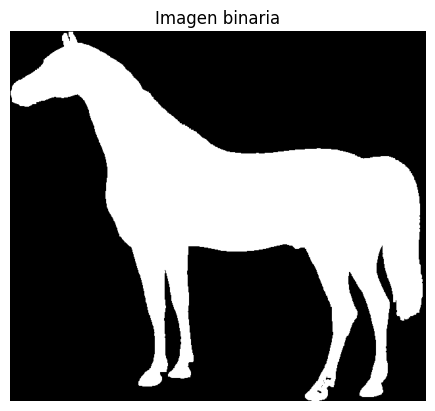

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt


# 1. Cargar imagen
ruta = input("Introduce la ruta del GIF: ")

imagen = Image.open(ruta)
imagen.seek(0)
imagen = imagen.convert("L")

matriz = np.array(imagen)
binaria = (matriz == 255).astype(np.uint8)

print("Tamaño:", matriz.shape)
print("Valores:", np.unique(matriz))

plt.imshow(binaria, cmap="gray")
plt.title("Imagen binaria")
plt.axis("off")
plt.show()

In [10]:
# 2. Obtener los bordes orientados
def obtener_bordes(imagen):
    alto, ancho = imagen.shape
    bordes = set()

    for y in range(alto):
        for x in range(ancho):

            if imagen[y, x] == 0:
                continue

            if y == 0 or imagen[y - 1, x] == 0:
                bordes.add(((y, x), (y, x + 1)))

            if x == ancho - 1 or imagen[y, x + 1] == 0:
                bordes.add(((y, x + 1), (y + 1, x + 1)))

            if y == alto - 1 or imagen[y + 1, x] == 0:
                bordes.add(((y + 1, x + 1), (y + 1, x)))

            if x == 0 or imagen[y, x - 1] == 0:
                bordes.add(((y + 1, x), (y, x)))

    return bordes


# 3. Recorrer el contorno
def recorrer_contorno(bordes):

    if not bordes:
        raise ValueError("No se encontró ningún objeto.")

    inicio = min(
        (p for p, _ in bordes),
        key=lambda p: (p[0], p[1])
    )

    primer_borde = (inicio, (inicio[0], inicio[1] + 1))

    if primer_borde not in bordes:
        raise ValueError("No se encontró el borde inicial.")

    salidas = {}

    for borde in bordes:
        salidas.setdefault(borde[0], []).append(borde)

    # Direcciones: derecha, abajo, izquierda, arriba
    desplazamientos = {
        0: (0, 1),
        1: (1, 0),
        2: (0, -1),
        3: (-1, 0)
    }

    coordenadas = [inicio]
    segmentos = []

    actual = primer_borde
    visitados = set()

    # Prioridad: derecha, recto, izquierda, atrás
    prioridad = [1, 0, 3, 2]

    while actual not in visitados:

        visitados.add(actual)

        p1, p2 = actual
        coordenadas.append(p2)

        dy = p2[0] - p1[0]
        dx = p2[1] - p1[1]

        direccion = next(
            d for d, delta in desplazamientos.items()
            if delta == (dy, dx)
        )

        segmentos.append(direccion)

        if p2 == inicio:
            break

        candidatos = [
            b for b in salidas.get(p2, [])
            if b not in visitados
        ]

        if not candidatos:
            raise ValueError("El contorno no pudo cerrarse.")

        def prioridad_borde(b):
            q1, q2 = b
            delta = (q2[0] - q1[0], q2[1] - q1[1])

            nueva = next(
                d for d, v in desplazamientos.items()
                if v == delta
            )

            return prioridad.index((nueva - direccion) % 4)

        actual = min(candidatos, key=prioridad_borde)

    if coordenadas[-1] != inicio:
        raise ValueError("El contorno no cerró correctamente.")

    return coordenadas, segmentos

# 4. Transformar F4 a 3OT
def convertir_f4_3ot(cadena):

    if not cadena:
        raise ValueError("La cadena está vacía.")

    if any(d not in range(4) for d in cadena):
        raise ValueError(
            "La cadena debe contener únicamente direcciones F4 (0, 1, 2, 3)."
        )

    n = len(cadena)
    cadena_3ot = []

    for i in range(n):

        actual = cadena[i]
        siguiente = cadena[(i + 1) % n]

        diferencia = (siguiente - actual) % 4

        if diferencia == 0:
            simbolo = 0

        elif diferencia == 1:
            simbolo = 1

        elif diferencia == 3:
            simbolo = 2

        else:
            raise ValueError(
                f"Giro de 180 grados no válido en posición {i}: "
                f"{actual} -> {siguiente}"
            )

        cadena_3ot.append(simbolo)

    return cadena_3ot

    # 5. Obtener los bordes
bordes = obtener_bordes(matriz)

# 6. Obtener la cadena F4
recorrido, cadena = recorrer_contorno(bordes)

# 7. Conversión F4 -> 3OT
cadena_3ot = convertir_f4_3ot(cadena)

# 8. Resultados
print("Cadena F4:")
print("".join(map(str, cadena)))

print("\nCadena 3OT:")
print("".join(map(str, cadena_3ot)))

print("\nLongitud F4:", len(cadena))
print("Longitud 3OT:", len(cadena_3ot))

Cadena F4:
00000001111010110101110110111010000000100100001000010010010010001001001001010100010010010010101001001100100100100100110010010100101001101010110101010010101001101011010110010101010101011010110110110110100100100100011001011011010011101010011001011010101010110010100101010101100101001010100101010101001011001011000110000011000101001100011000011000100110100101010101010010010010101010101010100010100101000101000100100010001001000001000000001000000000100000000000000000000000300001000000000300000000000003000000030000000003000000003000000000300000000000000030000000000000000003000000100000000000000001000000000010001000001000010000100010001000011000101000010100001030000000003000030000000000003000000000000010001000100011010000101010010011000101011001010101011100111001110101101111010111011011111011110111110111110111111111110111111111111111111211011112101111211110111121101111211111111111121111111111111111111111111111110111111101011111111111111011011112101011112110111111111111111111111211211